In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv("/content/insurance1.csv")

In [ ]:
df.shape

(1338, 7)

In [ ]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [ ]:
df.tail()

,age,sex,bmi,children,smoker,region,charges
1333,50,male,30.97,3,no,northwest,10600.5483
1334,18,female,31.92,0,no,northeast,2205.9808
1335,18,female,36.85,0,no,southeast,1629.8335
1336,21,female,25.80,0,no,southwest,2007.9450
1337,61,female,29.07,0,yes,northwest,29141.3603


In [ ]:
df.describe()

,age,bmi,children,charges,log_charges
count,1338.000000,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265,9.098828
std,14.049960,6.098187,1.205493,12110.011237,0.919379
min,18.000000,15.960000,0.000000,1121.873900,7.023647
25%,27.000000,26.296250,0.000000,4740.287150,8.464064
50%,39.000000,30.400000,1.000000,9382.033000,9.146658
75%,51.000000,34.693750,2.000000,16639.912515,9.719618
max,64.000000,53.130000,5.000000,63770.428010,11.063061


In [ ]:
df.isnull().sum()

,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


In [ ]:
df.dtypes

,0
age,int64
sex,object
bmi,float64
children,int64
smoker,object
region,object
charges,float64


In [ ]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [ ]:
df[df['charges'] <= 0]

,age,sex,bmi,children,smoker,region,charges


In [ ]:
# Shuningdek, ularning umumiy sonini aniqlash uchun:
print((df['charges'] <= 0).sum())

0


In [ ]:
df['log_charges'] = np.log1p(df['charges'])

In [ ]:
df.describe()

,age,bmi,children,charges,log_charges
count,1338.000000,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265,9.098828
std,14.049960,6.098187,1.205493,12110.011237,0.919379
min,18.000000,15.960000,0.000000,1121.873900,7.023647
25%,27.000000,26.296250,0.000000,4740.287150,8.464064
50%,39.000000,30.400000,1.000000,9382.033000,9.146658
75%,51.000000,34.693750,2.000000,16639.912515,9.719618
max,64.000000,53.130000,5.000000,63770.428010,11.063061


charges        1.000000
log_charges    0.892996
age            0.299008
bmi            0.198341
children       0.067998
Name: charges, dtype: float64


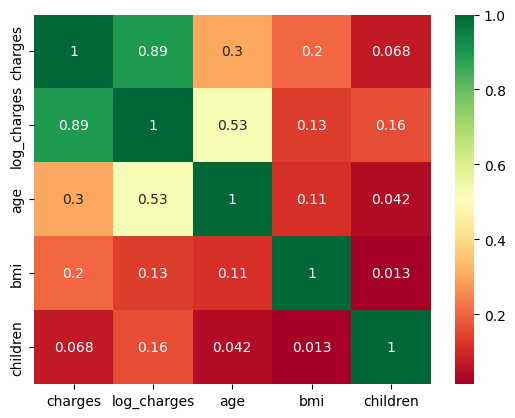

In [ ]:
nums = df.select_dtypes('number') # type number bo'ganlarini olish
# print(nums)
c = nums.corr()['charges']
print(c.sort_values(ascending=False).head())
cols = c.sort_values(ascending=False).head().index
sns.heatmap(nums[cols].corr(), annot=True, cmap='RdYlGn')

plt.show()

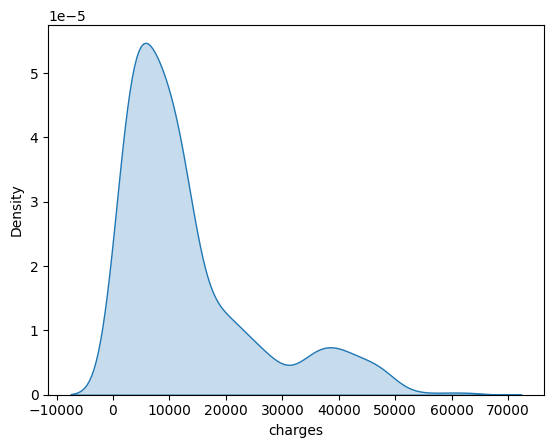

In [ ]:
sns.kdeplot(x=df['charges'], fill=True)
plt.show()

# charges leftsquid bo'lib turibdi, endi buni log transform qilish kerak

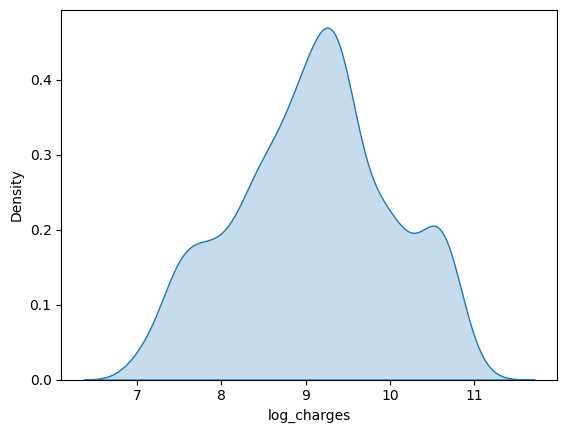

In [ ]:
sns.kdeplot(x=df['log_charges'], fill=True)
plt.show()
# log transformdan keyin to'girlandi

log_charges    1.000000
charges        0.892996
age            0.527807
children       0.161317
bmi            0.132678
Name: log_charges, dtype: float64


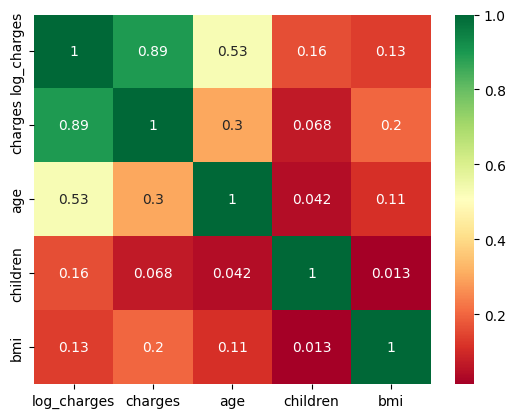

In [ ]:
nums = df.select_dtypes('number') # type number bo'ganlarini olish
# print(nums)
c = nums.corr()['log_charges']
print(c.sort_values(ascending=False).head())
cols = c.sort_values(ascending=False).head().index
sns.heatmap(nums[cols].corr(), annot=True, cmap='RdYlGn')

plt.show()

In [ ]:
# dublicate
# baseline model train qilish kerak edi eng birinchi r^2 hisoblash kerak edi
# yana train qilaman
# train qilsih jarayonida future engineering encoding scalling qilinadi.
# 2 ta future va keyin 3 ta feature
